# SELF LEARNING – LAB PROGRAM 2
## Hugging Face Hub, NumPy Convolution & Max-Pooling, and CNN for CIFAR-10

**Objectives**
1. Understand the Hugging Face Hub, datasets, and model cards.
2. Load CIFAR-10 from the Hugging Face Hub.
3. Implement 2D convolution and max-pooling using NumPy.
4. Observe the effect of kernel size, stride, and padding.
5. Build and evaluate a basic CNN for CIFAR-10 image classification.

**Suggested runtime:** Google Colab → Runtime → Change runtime type → T4 GPU (optional).  
Run the cells from top to bottom. The NumPy demonstrations run on CPU; the CNN can run on GPU if available.


## 1. Introduction to the Hugging Face Hub

The **Hugging Face Hub** is an online platform for sharing and discovering machine-learning resources.

- **Models:** pretrained models that can be downloaded and reused.
- **Datasets:** datasets used for training, validation, and testing.
- **Spaces:** interactive machine-learning applications.
- **Model card:** a README-style document describing a model, its intended use, training data, evaluation, limitations, and ethical considerations.

A dataset repository usually contains dataset files and a dataset card. A model repository usually contains model weights/configuration and a model card.


In [1]:
# Install the Hugging Face libraries
!pip -q install -U datasets huggingface_hub

In [2]:
from huggingface_hub import HfApi

api = HfApi()

# Search for CIFAR-10 dataset repositories on the Hub
dataset_results = api.list_datasets(search="cifar10", limit=5)
for item in dataset_results:
    print(item.id)

uoft-cs/cifar10
uoft-cs/cifar100
rafay/upside_down_detection_cifar100
student/CIFAR-10
arize-ai/cifar10_quality_drift


### 1.1 Load CIFAR-10 from the Hugging Face Hub

CIFAR-10 contains 60,000 colour images of size 32 × 32 pixels in 10 classes.
The standard split contains 50,000 training images and 10,000 test images.

We use the `datasets` library to download the dataset. If the Hub dataset repository changes or is temporarily unavailable, the fallback cell below loads CIFAR-10 through Keras.


In [3]:
from datasets import load_dataset

try:
    hf_dataset = load_dataset("uoft-cs/cifar10")
    print(hf_dataset)
    print("Available splits:", list(hf_dataset.keys()))
except Exception as error:
    print("Hugging Face dataset loading failed:", error)
    print("Use the Keras fallback cell below.")

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})
Available splits: ['train', 'test']


Example fields: dict_keys(['img', 'label'])


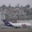

Label: 0


In [4]:
# Inspect one example when the Hugging Face dataset loaded successfully
if "hf_dataset" in globals():
    split_name = "train" if "train" in hf_dataset else list(hf_dataset.keys())[0]
    example = hf_dataset[split_name][0]
    print("Example fields:", example.keys())
    display(example["img"])
    print("Label:", example.get("label"))

### 1.2 Understand model cards

A model card helps users decide whether a model is appropriate and how to use it responsibly.
The next cell retrieves metadata for a public image-classification model. Internet access is required.


In [5]:
from huggingface_hub import model_info

try:
    info = model_info("google/vit-base-patch16-224")
    print("Model ID:", info.id)
    print("Pipeline tag:", info.pipeline_tag)
    print("Library:", info.library_name)
    print("Tags:", info.tags[:15] if info.tags else None)
    print("\nModel card data:")
    print(info.card_data)
except Exception as error:
    print("Could not retrieve model metadata:", error)
    print("Open https://huggingface.co/google/vit-base-patch16-224 to inspect its model card.")

Model ID: google/vit-base-patch16-224
Pipeline tag: image-classification
Library: transformers
Tags: ['transformers', 'pytorch', 'tf', 'jax', 'safetensors', 'vit', 'image-classification', 'vision', 'dataset:imagenet-1k', 'dataset:imagenet-21k', 'arxiv:2010.11929', 'arxiv:2006.03677', 'license:apache-2.0', 'endpoints_compatible', 'deploy:azure']

Model card data:
datasets:
- imagenet-1k
- imagenet-21k
license: apache-2.0
tags:
- vision
- image-classification
widget:
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/tiger.jpg
  example_title: Tiger
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/teapot.jpg
  example_title: Teapot
- src: https://huggingface.co/datasets/mishig/sample_images/resolve/main/palace.jpg
  example_title: Palace


## 2. Implement 2D Convolution using NumPy

A convolution kernel (filter) slides over an image. At each position, corresponding values are multiplied and summed to produce one output value.

For an input of height `H` and width `W`, kernel size `K`, padding `P`, and stride `S`:

\[
H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1
\qquad
W_{out}=\left\lfloor\frac{W+2P-K}{S}\right\rfloor+1
\]

- **Kernel size:** dimensions of the filter (for example, 3 × 3).
- **Stride:** number of pixels moved each time.
- **Padding:** extra border pixels added around the input. Zero-padding adds zeros.


In [6]:
import numpy as np

def conv2d(image, kernel, stride=1, padding=0):
    """Simple 2D convolution/cross-correlation for a single-channel image."""
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("image and kernel must both be 2D arrays")
    if stride < 1 or padding < 0:
        raise ValueError("stride must be >= 1 and padding must be >= 0")

    padded = np.pad(image, ((padding, padding), (padding, padding)),
                    mode="constant")
    kh, kw = kernel.shape
    h, w = padded.shape

    out_h = (h - kh) // stride + 1
    out_w = (w - kw) // stride + 1
    if out_h <= 0 or out_w <= 0:
        raise ValueError("Kernel is larger than the padded input")

    output = np.zeros((out_h, out_w), dtype=float)
    for i in range(out_h):
        for j in range(out_w):
            region = padded[i*stride:i*stride+kh,
                            j*stride:j*stride+kw]
            output[i, j] = np.sum(region * kernel)
    return output

# Example input image and edge-detection kernel
image = np.array([
    [1, 2, 3, 0, 1],
    [4, 5, 6, 1, 2],
    [7, 8, 9, 2, 3],
    [1, 2, 3, 4, 5],
    [2, 3, 4, 5, 6]
])

kernel = np.array([
    [ 1,  0, -1],
    [ 1,  0, -1],
    [ 1,  0, -1]
])

print("Input image:\n", image)
print("\nKernel:\n", kernel)
print("\nConvolution output (stride=1, padding=0):\n",
      conv2d(image, kernel, stride=1, padding=0))

Input image:
 [[1 2 3 0 1]
 [4 5 6 1 2]
 [7 8 9 2 3]
 [1 2 3 4 5]
 [2 3 4 5 6]]

Kernel:
 [[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]

Convolution output (stride=1, padding=0):
 [[-6. 12. 12.]
 [-6.  8.  8.]
 [-6.  2.  2.]]


## 3. Implement Max-Pooling using NumPy

Max-pooling reduces the spatial dimensions of a feature map. It divides the input into small regions and keeps the maximum value from each region.

For example, a 2 × 2 max-pooling window with stride 2 reduces a 4 × 4 input to a 2 × 2 output.


In [7]:
def max_pool2d(image, pool_size=2, stride=2):
    """Max-pooling for a single-channel 2D array (no padding)."""
    image = np.asarray(image)
    if image.ndim != 2:
        raise ValueError("image must be a 2D array")
    if pool_size < 1 or stride < 1:
        raise ValueError("pool_size and stride must be >= 1")

    h, w = image.shape
    out_h = (h - pool_size) // stride + 1
    out_w = (w - pool_size) // stride + 1
    if out_h <= 0 or out_w <= 0:
        raise ValueError("Pooling window is larger than the input")

    output = np.zeros((out_h, out_w), dtype=image.dtype)
    for i in range(out_h):
        for j in range(out_w):
            region = image[i*stride:i*stride+pool_size,
                           j*stride:j*stride+pool_size]
            output[i, j] = np.max(region)
    return output

feature_map = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 4],
    [3, 9, 5, 6]
])

print("Feature map:\n", feature_map)
print("\nMax-pooling output (2x2 window, stride=2):\n",
      max_pool2d(feature_map, pool_size=2, stride=2))

Feature map:
 [[1 3 2 4]
 [5 6 1 2]
 [7 2 8 4]
 [3 9 5 6]]

Max-pooling output (2x2 window, stride=2):
 [[6 4]
 [9 8]]


## 4. Explore kernel size, stride, and padding

Run the following experiment and compare the output shapes.

- Increasing **kernel size** generally reduces output height and width.
- Increasing **stride** skips more positions and reduces output size.
- Increasing **padding** adds border values and can preserve more spatial information.
- With a 3 × 3 kernel, stride 1, and padding 1, the output has the same height and width as the input.


In [8]:
# Use one input and compare several convolution settings
test_image = np.arange(1, 26).reshape(5, 5)
print("Input shape:", test_image.shape)

experiments = [
    ("3x3, stride=1, padding=0", 3, 1, 0),
    ("3x3, stride=1, padding=1", 3, 1, 1),
    ("3x3, stride=2, padding=0", 3, 2, 0),
    ("2x2, stride=1, padding=0", 2, 1, 0),
]

for description, k, s, p in experiments:
    sample_kernel = np.ones((k, k))
    result = conv2d(test_image, sample_kernel, stride=s, padding=p)
    print(f"\n{description}")
    print("Output shape:", result.shape)
    print(result)

Input shape: (5, 5)

3x3, stride=1, padding=0
Output shape: (3, 3)
[[ 63.  72.  81.]
 [108. 117. 126.]
 [153. 162. 171.]]

3x3, stride=1, padding=1
Output shape: (5, 5)
[[ 16.  27.  33.  39.  28.]
 [ 39.  63.  72.  81.  57.]
 [ 69. 108. 117. 126.  87.]
 [ 99. 153. 162. 171. 117.]
 [ 76. 117. 123. 129.  88.]]

3x3, stride=2, padding=0
Output shape: (2, 2)
[[ 63.  81.]
 [153. 171.]]

2x2, stride=1, padding=0
Output shape: (4, 4)
[[16. 20. 24. 28.]
 [36. 40. 44. 48.]
 [56. 60. 64. 68.]
 [76. 80. 84. 88.]]


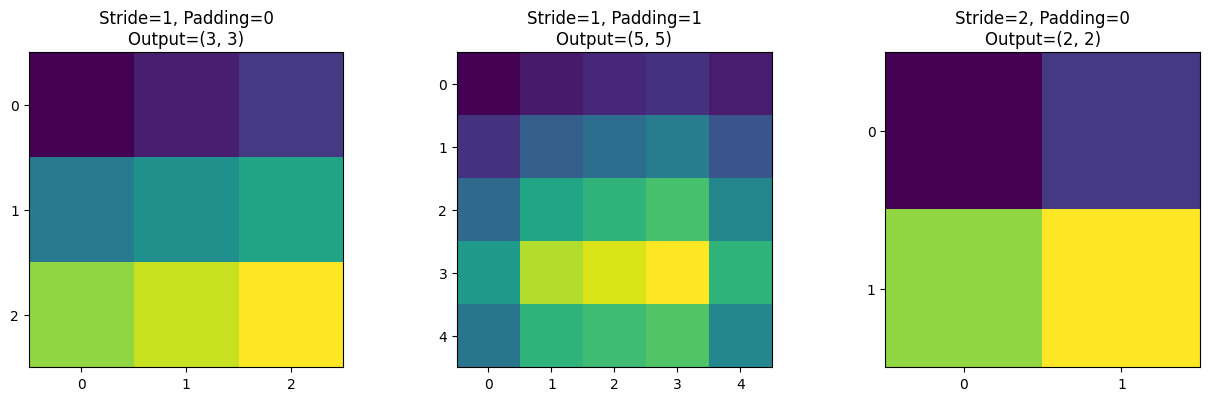

In [9]:
# Visualize how a 3x3 kernel responds to different stride and padding values
import matplotlib.pyplot as plt

settings = [(1, 0), (1, 1), (2, 0)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (s, p) in zip(axes, settings):
    result = conv2d(test_image, np.ones((3, 3)), stride=s, padding=p)
    ax.imshow(result, cmap="viridis")
    ax.set_title(f"Stride={s}, Padding={p}\nOutput={result.shape}")
    ax.set_xticks(range(result.shape[1]))
    ax.set_yticks(range(result.shape[0]))

plt.tight_layout()
plt.show()

## 5. Prepare CIFAR-10 for CNN training

We first try to use the Hugging Face dataset loaded above. The code handles common image-column names. If loading from the Hub was unsuccessful, it downloads the same dataset using Keras.

To keep the lab practical on free Colab hardware, the default training subset is smaller than the full dataset. Set `USE_FULL_DATASET = True` if you have enough time and memory.


In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

USE_FULL_DATASET = False
TRAIN_LIMIT = 12000
TEST_LIMIT = 3000

def prepare_hf_split(split):
    # Detect the image column
    image_key = next((k for k in ["img", "image"] if k in split.column_names), None)
    label_key = "label" if "label" in split.column_names else "labels"
    if image_key is None:
        raise ValueError("Could not find an image column in the Hugging Face dataset")

    images = []
    labels = []
    for item in split:
        img = item[image_key].convert("RGB").resize((32, 32))
        images.append(np.asarray(img, dtype=np.uint8))
        labels.append(int(item[label_key]))
    return np.array(images), np.array(labels, dtype=np.int64)

try:
    if "hf_dataset" not in globals():
        raise RuntimeError("Hugging Face dataset was not loaded")
    train_split = hf_dataset["train"]
    test_split = hf_dataset["test"]
    x_train, y_train = prepare_hf_split(train_split)
    x_test, y_test = prepare_hf_split(test_split)
    print("Using CIFAR-10 from Hugging Face Hub")
except Exception as error:
    print("Using Keras CIFAR-10 fallback:", error)
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
    y_train = y_train.squeeze()
    y_test = y_test.squeeze()

if not USE_FULL_DATASET:
    x_train, y_train = x_train[:TRAIN_LIMIT], y_train[:TRAIN_LIMIT]
    x_test, y_test = x_test[:TEST_LIMIT], y_test[:TEST_LIMIT]

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

print("Training images:", x_train.shape, "Labels:", y_train.shape)
print("Testing images:", x_test.shape, "Labels:", y_test.shape)

TensorFlow version: 2.21.0
GPU devices: []
Using CIFAR-10 from Hugging Face Hub
Training images: (12000, 32, 32, 3) Labels: (12000,)
Testing images: (3000, 32, 32, 3) Labels: (3000,)


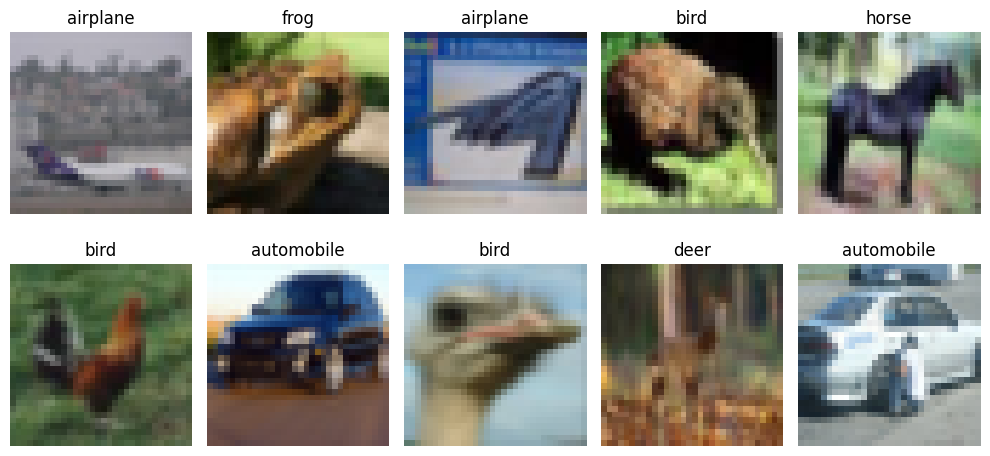

In [11]:
# Display sample images
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Build a basic CNN for CIFAR-10 classification

A Convolutional Neural Network (CNN) learns visual features from images.

**Architecture**
1. Input: 32 × 32 × 3 colour image.
2. Convolution + ReLU: learns simple patterns such as edges.
3. Max-pooling: reduces feature-map size.
4. A second convolution and pooling stage: learns more complex features.
5. Flatten + Dense: performs classification.
6. Output: 10 neurons, one for each CIFAR-10 class.

Pixel values are normalized from 0–255 to 0–1.


In [12]:
# Normalize images and convert labels to integer class IDs
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Train the CNN
EPOCHS = 8
BATCH_SIZE = 64

history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 30s 165ms/step - accuracy: 0.2758 - loss: 1.9544 - val_accuracy: 0.3942 - val_loss: 1.6793
Epoch 2/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 28s 164ms/step - accuracy: 0.3997 - loss: 1.6232 - val_accuracy: 0.4942 - val_loss: 1.4309
Epoch 3/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 41s 164ms/step - accuracy: 0.4762 - loss: 1.4514 - val_accuracy: 0.5300 - val_loss: 1.3287
Epoch 4/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 41s 164ms/step - accuracy: 0.5273 - loss: 1.3136 - val_accuracy: 0.5392 - val_loss: 1.2738
Epoch 5/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 41s 163ms/step - accuracy: 0.5652 - loss: 1.2095 - val_accuracy: 0.5958 - val_loss: 1.1602
Epoch 6/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 27s 160ms/step - accuracy: 0.6090 - loss: 1.1039 - val_accuracy: 0.6192 - val_loss: 1.1133
Epoch 7/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 41s 162ms/step - accuracy: 0.6420 - loss: 1.0110 - val_accuracy: 0.6208 - val_loss: 1.1071
Epoch 8/8
169/169 ━━━━━━━━━━━━━━━━━━━━ 40s 156ms/step - accuracy: 0.6800 - loss: 0.9086 - 

## 7. Evaluate the CNN

Test accuracy measures the fraction of test images classified correctly. Accuracy depends on the number of training examples, epochs, hardware, and random initialization; it is not expected to match a published benchmark when using a subset.


In [14]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 1.0909
Test accuracy: 61.43%


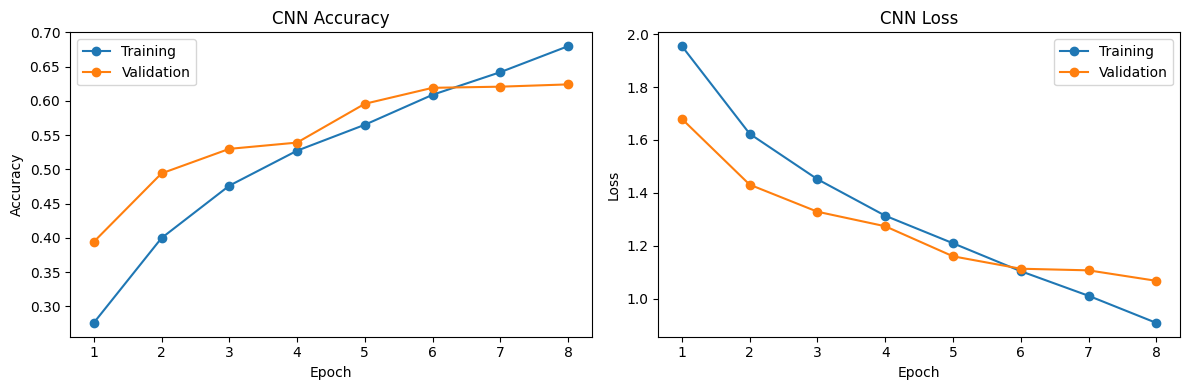

In [15]:
# Plot training and validation accuracy/loss
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

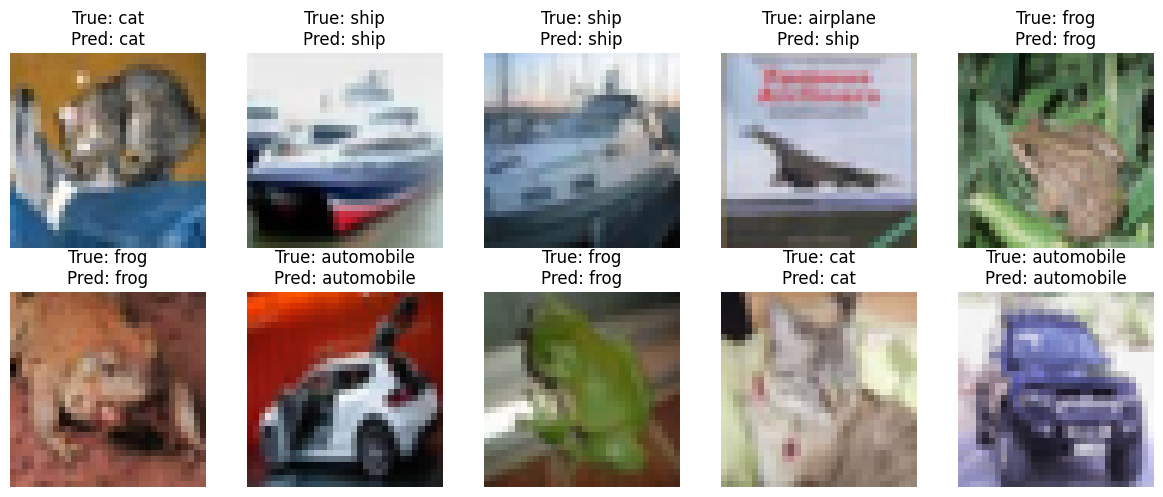

In [16]:
# Predict labels for a few test images
probabilities = model.predict(x_test[:10], verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    actual = class_names[int(y_test[i])]
    predicted = class_names[int(predicted_labels[i])]
    plt.title(f"True: {actual}\nPred: {predicted}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 8. Save the trained model

The model is saved in Keras format. You can download it from the Colab file browser or use the download cell.


In [17]:
model.save("cifar10_basic_cnn.keras")
print("Saved as cifar10_basic_cnn.keras")

from google.colab import files
files.download("cifar10_basic_cnn.keras")

Saved as cifar10_basic_cnn.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Results and observations

Fill in the actual values after running the notebook.

| Experiment | Observation |
|---|---|
| 3 × 3 kernel, stride 1, padding 0 | Output becomes smaller than input |
| 3 × 3 kernel, stride 1, padding 1 | Spatial dimensions are preserved |
| Larger stride | Fewer output positions are produced |
| Max-pooling 2 × 2, stride 2 | Reduces height and width approximately by half |
| CNN on CIFAR-10 | Learns to classify images into 10 categories |


## 10. Conclusion

In this lab, we explored the Hugging Face Hub and learned how datasets and model cards are used in machine learning. We implemented 2D convolution and max-pooling from scratch using NumPy and observed how kernel size, stride, and padding affect output dimensions. Finally, we built, trained, and evaluated a CNN for CIFAR-10 image classification.

